In [1]:
import pandas as pd
import numpy as np
import json
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

from pathlib import Path

def localizar_edas():
    """Busca Data/raw y Data/processed en Jupyter, Visual Studio Code y Colab.

    Orden de búsqueda: carpeta del notebook, directorio de trabajo y, en Colab, /content.
    Sirve con la estructura Data/raw y Data/processed, y también si los CSV de raw
    o de processed están sueltos en una de esas carpetas (en Colab, junto a sample_data).
    """
    from pathlib import Path
    import json

    saltar = {
        ".config", "sample_data", "drive", ".git", "__pycache__",
        "node_modules", ".ipynb_checkpoints", "site-packages",
    }
    marcas_raw = (
        "artistainfo.json",
        "cancioninfo.json",
        "fecha.json",
        "favoritos.json",
        "listas.json",
        "popularidad.json",
        "features_30_sec.csv",
        "features_3_sec.csv",
    )
    marcas_processed = (
        "cancion.csv",
        "cancion_ids.csv",
        "id_disco.csv",
        "id_genero.csv",
        "fecha_publicacion.csv",
        "fecha_limpio.csv",
        "artistas.csv",
        "artistas_ids.csv",
        "artistas_sql.csv",
        "id_artistas_sql.csv",
        "favoritos.csv",
        "favoritos_eda.csv",
        "listas_canciones.csv",
        "popularidad.csv",
        "features_30_sec.csv",
        "features_3_sec.csv",
    )

    def directorio_notebook():
        try:
            return Path(__vsc_ipynb_file__).resolve().parent
        except NameError:
            pass
        try:
            from urllib.request import urlopen
            try:
                from ipykernel.connect import get_connection_file
            except ImportError:
                from ipykernel import get_connection_file
            conexion = Path(get_connection_file())
            kernel_id = conexion.name.replace("kernel-", "").replace(".json", "")
            servidores = list(conexion.parent.glob("jpserver-*.json"))[:3]
            for servidor in servidores:
                try:
                    info = json.loads(servidor.read_text(encoding="utf-8"))
                except (OSError, json.JSONDecodeError):
                    continue
                url = str(info.get("url", "")).rstrip("/")
                raiz = info.get("root_dir")
                if not url or not raiz:
                    continue
                api = url + "/api/sessions"
                token = info.get("token") or ""
                if token:
                    api += "?token=" + token
                try:
                    with urlopen(api, timeout=0.8) as respuesta:
                        sesiones = json.loads(respuesta.read().decode())
                except Exception:
                    continue
                for sesion in sesiones:
                    kid = (sesion.get("kernel") or {}).get("id")
                    if kid != kernel_id:
                        continue
                    cuaderno = sesion.get("notebook") or {}
                    relativo = cuaderno.get("path") or sesion.get("path")
                    if relativo:
                        return (Path(raiz) / relativo).resolve().parent
        except Exception:
            pass
        return None

    bases = []
    notebook = directorio_notebook()
    if notebook is not None:
        bases.append(notebook)
    cwd = Path.cwd().resolve()
    if cwd not in bases:
        bases.append(cwd)
    content = Path("/content")
    if content.is_dir():
        content = content.resolve()
        if content not in bases:
            bases.append(content)
        drive = content / "drive" / "MyDrive"
        if drive.is_dir() and drive not in bases:
            bases.append(drive)

    def buscar(nombre, marcas):
        opuesta = "processed" if nombre == "raw" else "raw"

        def tiene(carpeta):
            try:
                return any((carpeta / marca).is_file() for marca in marcas)
            except OSError:
                return False

        def nombrada(directorio):
            anidada = directorio / "Data" / nombre
            if tiene(anidada):
                return anidada
            if directorio.name == nombre and tiene(directorio):
                return directorio
            return None

        def hijos(directorio, profundidad, limite):
            if profundidad < 0 or limite[0] <= 0 or not directorio.is_dir():
                return None
            try:
                entradas = list(directorio.iterdir())
            except OSError:
                return None
            for hijo in entradas:
                if not hijo.is_dir() or hijo.name.startswith(".") or hijo.name in saltar:
                    continue
                limite[0] -= 1
                hallazgo = nombrada(hijo)
                if hallazgo is not None:
                    return hallazgo
                if limite[0] <= 0:
                    return None
                hallazgo = hijos(hijo, profundidad - 1, limite)
                if hallazgo is not None:
                    return hallazgo
                if limite[0] <= 0:
                    return None
            return None

        for base in bases:
            if not base.is_dir():
                continue
            hallazgo = nombrada(base)
            if hallazgo is not None:
                return hallazgo
            for padre in list(base.parents)[:6]:
                hallazgo = nombrada(padre)
                if hallazgo is not None:
                    return hallazgo
            profundidad = 3 if base.name in {"content", "MyDrive"} else 2
            hallazgo = hijos(base, profundidad, [400])
            if hallazgo is not None:
                return hallazgo
            if base.name != opuesta and tiene(base):
                return base
        return None

    cruda = buscar("raw", marcas_raw)
    procesados = buscar("processed", marcas_processed)

    if cruda is None and procesados is None:
        raise FileNotFoundError(
            "No se encuentran los datos. "
            "Tiene que existir la carpeta Data/raw o Data/processed, "
            "o los CSV en la carpeta del notebook, en el directorio de trabajo "
            "o, en Colab, en /content junto a sample_data."
        )

    if cruda is not None and procesados is None:
        if cruda.name == "raw":
            procesados = cruda.parent / "processed"
        else:
            procesados = cruda
        procesados.mkdir(parents=True, exist_ok=True)
    elif procesados is not None and cruda is None:
        if procesados.name == "processed":
            cruda = procesados.parent / "raw"
        else:
            cruda = procesados

    return cruda, procesados
DATA_RAW, DATA_PROCESSED = localizar_edas()
print("Raw:", DATA_RAW)
print("Processed:", DATA_PROCESSED)

DATA_PROCESSED.mkdir(parents=True, exist_ok=True)


Saving features_3_sec.csv to features_3_sec.csv


In [2]:
df = pd.read_csv(DATA_RAW / "features_3_sec.csv")
df


,filename,length,chroma_stft_mean,chroma_stft_var,rms_mean,rms_var,spectral_centroid_mean,spectral_centroid_var,spectral_bandwidth_mean,spectral_bandwidth_var,...,mfcc16_var,mfcc17_mean,mfcc17_var,mfcc18_mean,mfcc18_var,mfcc19_mean,mfcc19_var,mfcc20_mean,mfcc20_var,label
0,blues.00000.0.wav,66149,0.335406,0.091048,0.130405,0.003521,1773.065032,167541.630869,1972.744388,117335.771563,...,39.687145,-3.241280,36.488243,0.722209,38.099152,-5.050335,33.618073,-0.243027,43.771767,blues
1,blues.00000.1.wav,66149,0.343065,0.086147,0.112699,0.001450,1816.693777,90525.690866,2010.051501,65671.875673,...,64.748276,-6.055294,40.677654,0.159015,51.264091,-2.837699,97.030830,5.784063,59.943081,blues
2,blues.00000.2.wav,66149,0.346815,0.092243,0.132003,0.004620,1788.539719,111407.437613,2084.565132,75124.921716,...,67.336563,-1.768610,28.348579,2.378768,45.717648,-1.938424,53.050835,2.517375,33.105122,blues
3,blues.00000.3.wav,66149,0.363639,0.086856,0.132565,0.002448,1655.289045,111952.284517,1960.039988,82913.639269,...,47.739452,-3.841155,28.337118,1.218588,34.770935,-3.580352,50.836224,3.630866,32.023678,blues
4,blues.00000.4.wav,66149,0.335579,0.088129,0.143289,0.001701,1630.656199,79667.267654,1948.503884,60204.020268,...,30.336359,0.664582,45.880913,1.689446,51.363583,-3.392489,26.738789,0.536961,29.146694,blues
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9985,rock.00099.5.wav,66149,0.349126,0.080515,0.050019,0.000097,1499.083005,164266.886443,1718.707215,85931.574523,...,42.485981,-9.094270,38.326839,-4.246976,31.049839,-5.625813,48.804092,1.818823,38.966969,rock
9986,rock.00099.6.wav,66149,0.372564,0.082626,0.057897,0.000088,1847.965128,281054.935973,1906.468492,99727.037054,...,32.415203,-12.375726,66.418587,-3.081278,54.414265,-11.960546,63.452255,0.428857,18.697033,rock
9987,rock.00099.7.wav,66149,0.347481,0.089019,0.052403,0.000701,1346.157659,662956.246325,1561.859087,138762.841945,...,78.228149,-2.524483,21.778994,4.809936,25.980829,1.775686,48.582378,-0.299545,41.586990,rock
9988,rock.00099.8.wav,66149,0.387527,0.084815,0.066430,0.000320,2084.515327,203891.039161,2018.366254,22860.992562,...,28.323744,-5.363541,17.209942,6.462601,21.442928,2.354765,24.843613,0.675824,12.787750,rock


#Primer análisis exploratorio

In [3]:
#Revisamos el nombre de todas las columnas (variables) para estudiarlas ya que parecen variables muy específicas para la identificación de sonidos
df.columns

Index(['filename', 'length', 'chroma_stft_mean', 'chroma_stft_var', 'rms_mean',
       'rms_var', 'spectral_centroid_mean', 'spectral_centroid_var',
       'spectral_bandwidth_mean', 'spectral_bandwidth_var', 'rolloff_mean',
       'rolloff_var', 'zero_crossing_rate_mean', 'zero_crossing_rate_var',
       'harmony_mean', 'harmony_var', 'perceptr_mean', 'perceptr_var', 'tempo',
       'mfcc1_mean', 'mfcc1_var', 'mfcc2_mean', 'mfcc2_var', 'mfcc3_mean',
       'mfcc3_var', 'mfcc4_mean', 'mfcc4_var', 'mfcc5_mean', 'mfcc5_var',
       'mfcc6_mean', 'mfcc6_var', 'mfcc7_mean', 'mfcc7_var', 'mfcc8_mean',
       'mfcc8_var', 'mfcc9_mean', 'mfcc9_var', 'mfcc10_mean', 'mfcc10_var',
       'mfcc11_mean', 'mfcc11_var', 'mfcc12_mean', 'mfcc12_var', 'mfcc13_mean',
       'mfcc13_var', 'mfcc14_mean', 'mfcc14_var', 'mfcc15_mean', 'mfcc15_var',
       'mfcc16_mean', 'mfcc16_var', 'mfcc17_mean', 'mfcc17_var', 'mfcc18_mean',
       'mfcc18_var', 'mfcc19_mean', 'mfcc19_var', 'mfcc20_mean', 'mfcc20_var',
  

Buscamos la información en una fuente externa para hacernos una idea de con qué estamos trabajando

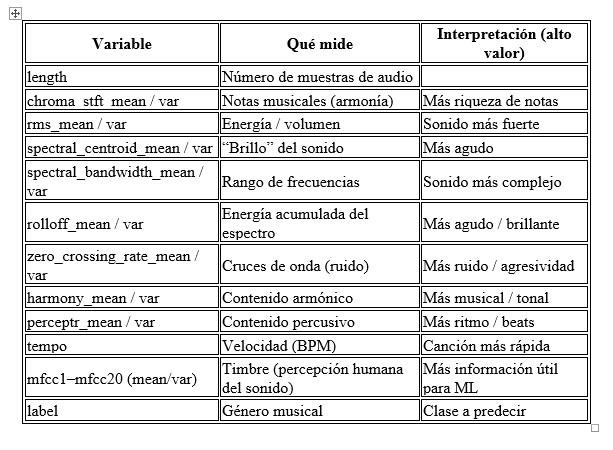

In [4]:
#Estudiamos el tipo de variable y si existen nulos
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9990 entries, 0 to 9989
Data columns (total 60 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   filename                 9990 non-null   object 
 1   length                   9990 non-null   int64  
 2   chroma_stft_mean         9990 non-null   float64
 3   chroma_stft_var          9990 non-null   float64
 4   rms_mean                 9990 non-null   float64
 5   rms_var                  9990 non-null   float64
 6   spectral_centroid_mean   9990 non-null   float64
 7   spectral_centroid_var    9990 non-null   float64
 8   spectral_bandwidth_mean  9990 non-null   float64
 9   spectral_bandwidth_var   9990 non-null   float64
 10  rolloff_mean             9990 non-null   float64
 11  rolloff_var              9990 non-null   float64
 12  zero_crossing_rate_mean  9990 non-null   float64
 13  zero_crossing_rate_var   9990 non-null   float64
 14  harmony_mean            

Primeros vistazos a la tabla general con head, tail y sample

In [5]:
df.head()

,filename,length,chroma_stft_mean,chroma_stft_var,rms_mean,rms_var,spectral_centroid_mean,spectral_centroid_var,spectral_bandwidth_mean,spectral_bandwidth_var,...,mfcc16_var,mfcc17_mean,mfcc17_var,mfcc18_mean,mfcc18_var,mfcc19_mean,mfcc19_var,mfcc20_mean,mfcc20_var,label
0,blues.00000.0.wav,66149,0.335406,0.091048,0.130405,0.003521,1773.065032,167541.630869,1972.744388,117335.771563,...,39.687145,-3.241280,36.488243,0.722209,38.099152,-5.050335,33.618073,-0.243027,43.771767,blues
1,blues.00000.1.wav,66149,0.343065,0.086147,0.112699,0.001450,1816.693777,90525.690866,2010.051501,65671.875673,...,64.748276,-6.055294,40.677654,0.159015,51.264091,-2.837699,97.030830,5.784063,59.943081,blues
2,blues.00000.2.wav,66149,0.346815,0.092243,0.132003,0.004620,1788.539719,111407.437613,2084.565132,75124.921716,...,67.336563,-1.768610,28.348579,2.378768,45.717648,-1.938424,53.050835,2.517375,33.105122,blues
3,blues.00000.3.wav,66149,0.363639,0.086856,0.132565,0.002448,1655.289045,111952.284517,1960.039988,82913.639269,...,47.739452,-3.841155,28.337118,1.218588,34.770935,-3.580352,50.836224,3.630866,32.023678,blues
4,blues.00000.4.wav,66149,0.335579,0.088129,0.143289,0.001701,1630.656199,79667.267654,1948.503884,60204.020268,...,30.336359,0.664582,45.880913,1.689446,51.363583,-3.392489,26.738789,0.536961,29.146694,blues


In [6]:
df.tail()

,filename,length,chroma_stft_mean,chroma_stft_var,rms_mean,rms_var,spectral_centroid_mean,spectral_centroid_var,spectral_bandwidth_mean,spectral_bandwidth_var,...,mfcc16_var,mfcc17_mean,mfcc17_var,mfcc18_mean,mfcc18_var,mfcc19_mean,mfcc19_var,mfcc20_mean,mfcc20_var,label
9985,rock.00099.5.wav,66149,0.349126,0.080515,0.050019,0.000097,1499.083005,164266.886443,1718.707215,85931.574523,...,42.485981,-9.094270,38.326839,-4.246976,31.049839,-5.625813,48.804092,1.818823,38.966969,rock
9986,rock.00099.6.wav,66149,0.372564,0.082626,0.057897,0.000088,1847.965128,281054.935973,1906.468492,99727.037054,...,32.415203,-12.375726,66.418587,-3.081278,54.414265,-11.960546,63.452255,0.428857,18.697033,rock
9987,rock.00099.7.wav,66149,0.347481,0.089019,0.052403,0.000701,1346.157659,662956.246325,1561.859087,138762.841945,...,78.228149,-2.524483,21.778994,4.809936,25.980829,1.775686,48.582378,-0.299545,41.586990,rock
9988,rock.00099.8.wav,66149,0.387527,0.084815,0.066430,0.000320,2084.515327,203891.039161,2018.366254,22860.992562,...,28.323744,-5.363541,17.209942,6.462601,21.442928,2.354765,24.843613,0.675824,12.787750,rock
9989,rock.00099.9.wav,66149,0.369293,0.086759,0.050524,0.000067,1634.330126,411429.169769,1867.422378,119722.211518,...,38.801735,-11.598399,58.983097,-0.178517,55.761299,-6.903252,39.485901,-3.412534,31.727489,rock


In [7]:
df.sample(5)

,filename,length,chroma_stft_mean,chroma_stft_var,rms_mean,rms_var,spectral_centroid_mean,spectral_centroid_var,spectral_bandwidth_mean,spectral_bandwidth_var,...,mfcc16_var,mfcc17_mean,mfcc17_var,mfcc18_mean,mfcc18_var,mfcc19_mean,mfcc19_var,mfcc20_mean,mfcc20_var,label
3261,disco.00026.7.wav,66149,0.391349,0.091169,0.142154,0.001393,3115.587108,446276.335803,2975.583513,95897.480623,...,54.849548,2.783870,58.148842,0.105740,61.141331,-1.345679,85.581429,0.018797,65.718315,disco
2173,country.00017.8.wav,66149,0.374916,0.071119,0.091423,0.000168,1481.623009,92418.628206,2004.262475,67157.343849,...,14.341934,-5.363901,15.152321,-1.174508,26.828245,3.810934,19.658831,-3.473490,27.087698,country
3649,disco.00065.5.wav,66149,0.475857,0.081954,0.183407,0.004448,1973.448004,295703.098344,2139.705398,95644.175790,...,46.473488,0.351484,51.551716,5.016062,38.425259,-4.792390,62.832706,-2.971198,48.840897,disco
3217,disco.00022.3.wav,66149,0.409492,0.088437,0.129808,0.004659,3825.575419,868366.105682,3288.242792,91044.965885,...,25.348997,-4.273517,58.586155,-2.821961,66.960533,-0.208271,70.077133,0.546173,64.309509,disco
5683,jazz.00069.1.wav,66149,0.216544,0.081317,0.122583,0.001065,1905.825928,95553.603133,1967.437308,78102.144462,...,27.361694,-8.789797,49.796974,-10.355694,96.743629,-9.100101,176.512527,-5.538702,161.934143,jazz


Confirmamos que no existen nulos

In [8]:
df.isna().sum()

,0
filename,0
length,0
chroma_stft_mean,0
chroma_stft_var,0
rms_mean,0
rms_var,0
spectral_centroid_mean,0
spectral_centroid_var,0
spectral_bandwidth_mean,0
spectral_bandwidth_var,0


Es importante identificar los valores duplicados en el dataframe por si se deben a errores en la propia base de datos.

In [9]:
# Cuantas filas tenemos duplicadas en el dataset
num_dupl = df.duplicated().sum()
print('Duplicados: ', num_dupl)

Duplicados:  0


Estadísticos básicos

In [10]:
#Aplicamos describe en la variable lenght
df["length"].describe()

,length
count,9990.0
mean,66149.0
std,0.0
min,66149.0
25%,66149.0
50%,66149.0
75%,66149.0
max,66149.0


**Conclusión:** length representa el número de muestras de audio del fragmento y presenta una desviación estándar nula, ya que los registros corresponden aproximadamente a 3 segundos de audio, por lo que probablemente tenga poca capacidad discriminativa para distinguir géneros musicales.

In [ ]:
#Aplicamos .describe en cada columna que termine en .mean agrupando además por género
cols_mean = [col for col in df.columns if col.endswith("mean")]
resultado = df.groupby("label")[cols_mean].describe().reset_index()
display(resultado)

label chroma_stft_mean                                          \
                        count      mean       std       min       25%   
0      blues           1000.0  0.342438  0.065894  0.199890  0.291327   
1  classical            998.0  0.264508  0.062357  0.116085  0.221372   
2    country            997.0  0.344996  0.054793  0.153389  0.304917   
3      disco            999.0  0.416377  0.059114  0.166253  0.382689   
4     hiphop            998.0  0.454590  0.059884  0.107108  0.418345   
5       jazz           1000.0  0.297520  0.070013  0.133362  0.249051   
6      metal           1000.0  0.480162  0.067344  0.285558  0.437449   
7        pop           1000.0  0.398089  0.070325  0.170542  0.352359   
8     reggae           1000.0  0.408984  0.068659  0.170663  0.365212   
9       rock            998.0  0.387546  0.059499  0.197283  0.349173   

                                rms_mean  ... mfcc19_mean             \
        50%       75%       max    count  ...         75%        max   
0  0.339325  0.395060  0.508660   1000.0  ...   -0.350392  20.927423   
1  0.257786  0.296684  0.738563    998.0  ...    2.427827  29.503691   
2  0.347878  0.385325  0.488880    997.0  ...   -0.225523  14.599508   
3  0.417695  0.451807  0.626246    999.0  ...   -0.288990  17.401411   
4  0.453542  0.489934  0.652983    998.0  ...    0.289870  22.366034   
5  0.291177  0.343632  0.508517   1000.0  ...    1.382092  31.365425   
6  0.479812  0.524742  0.667934   1000.0  ...   -2.773472   9.731807   
7  0.400165  0.444507  0.602595   1000.0  ...    3.679147  15.039911   
8  0.402010  0.452150  0.749481   1000.0  ...    0.333237  10.427372   
9  0.388106  0.430135  0.580280    998.0  ...   -1.349813  18.817728   

  mfcc20_mean                                                               \
        count      mean       std        min       25%       50%       75%   
0      1000.0 -2.527042  6.045119 -24.518272 -5.207671 -1.830272  1.583115   
1       998.0 -0.980228  7.124794 -35.640659 -5.154257 -1.678824  2.734061   
2       997.0 -2.885829  4.738889 -19.054577 -5.719793 -3.006526 -0.112072   
3       999.0  0.652601  4.388442 -13.665002 -2.159363  0.375754  3.335919   
4       998.0 -0.680143  4.483242 -11.884938 -3.627409 -1.276718  1.331117   
5      1000.0 -1.857287  6.140473 -31.903685 -5.606354 -1.998328  1.722670   
6      1000.0  1.561031  4.268619 -14.577498 -1.323924  1.905594  4.292558   
7      1000.0  0.319481  4.445481 -15.242114 -2.559045  0.150896  3.055651   
8      1000.0 -1.487579  4.158409 -16.976492 -3.856824 -1.484984  1.091618   
9       998.0 -1.295585  4.009761 -14.701604 -3.727486 -1.427769  1.011013   

              
         max  
0  16.433592  
1  23.925459  
2  18.994617  
3  16.739954  
4  27.121729  
5  34.212101  
6  14.396937  
7  22.153114  
8  13.058143  
9  12.254066  

[10 rows x 225 columns]

No es muy legible, resumimos solo con los estadísticos de media y desviación estándar

In [ ]:
#Resumen de la info más relevante para diferenciar entre géneros
resumen = (df.groupby("label")[cols_mean].agg(["mean", "std"])).reset_index()

display(resumen)

label chroma_stft_mean            rms_mean            \
                         mean       std      mean       std   
0      blues         0.342438  0.065894  0.136025  0.055486   
1  classical         0.264508  0.062357  0.042812  0.040542   
2    country         0.344996  0.054793  0.125690  0.052365   
3      disco         0.416377  0.059114  0.136209  0.045136   
4     hiphop         0.454590  0.059884  0.178219  0.064961   
5       jazz         0.297520  0.070013  0.086641  0.048367   
6      metal         0.480162  0.067344  0.153454  0.065854   
7        pop         0.398089  0.070325  0.199640  0.064565   
8     reggae         0.408984  0.068659  0.122433  0.053072   
9       rock         0.387546  0.059499  0.127368  0.047638   

  spectral_centroid_mean             spectral_bandwidth_mean              \
                    mean         std                    mean         std   
0            1726.067889  554.577835             1930.849650  356.146418   
1            1351.320102  412.934687             1519.531577  311.552298   
2            1891.187623  611.396470             2096.407344  462.687097   
3            2617.284955  510.231617             2512.355778  368.037392   
4            2521.518383  542.218871             2512.284466  374.721303   
5            1790.281688  723.024092             2019.764282  582.749185   
6            2600.881732  409.333881             2242.819811  225.439391   
7            3069.993025  646.813553             3006.802982  353.365695   
8            2182.213624  674.519161             2309.796710  407.649323   
9            2239.969555  529.125630             2262.222782  371.703239   

  rolloff_mean  ... mfcc16_mean           mfcc17_mean           mfcc18_mean  \
          mean  ...        mean       std        mean       std        mean   
0  3632.913078  ...    0.738590  7.199835   -7.628242  5.129495   -1.052426   
1  2475.817622  ...    1.520216  6.707791   -0.181774  6.161586    0.828762   
2  3938.471613  ...   -0.107398  5.790628   -5.821965  4.954187   -0.141678   
3  5514.648263  ...    1.449759  4.564216   -4.483338  4.870186    1.318948   
4  5327.690463  ...    2.755063  4.840376   -3.091336  3.824852    1.521220   
5  3744.724733  ...    0.905286  6.816567   -1.783814  6.072655   -0.640314   
6  5123.753216  ...    5.801267  3.850318   -8.284396  3.498087    3.206265   
7  6647.631499  ...   -0.961011  4.964405   -0.362038  4.942916    0.532565   
8  4586.938330  ...    1.157193  4.312134   -3.772454  4.620179    1.203878   
9  4664.782987  ...    1.221075  4.493353   -6.577367  5.053884    0.621645   

            mfcc19_mean           mfcc20_mean            
        std        mean       std        mean       std  
0  5.537718   -3.878884  5.644743   -2.527042  6.045119  
1  6.364840   -1.210227  6.459362   -0.980228  7.124794  
2  5.648253   -2.967412  4.545068   -2.885829  4.738889  
3  4.615645   -3.097415  4.435147    0.652601  4.388442  
4  4.795795   -1.844438  4.324047   -0.680143  4.483242  
5  5.449601   -1.374468  5.588428   -1.857287  6.140473  
6  3.711829   -5.025991  4.058990    1.561031  4.268619  
7  5.029436    0.855289  4.423384    0.319481  4.445481  
8  4.209994   -2.257146  3.809898   -1.487579  4.158409  
9  4.650682   -4.173846  4.557610   -1.295585  4.009761  

[10 rows x 57 columns]

In [ ]:
#Trasponemos para que sea aún más legible
resumen.T

0            1            2  \
label                               blues    classical      country   
chroma_stft_mean        mean     0.342438     0.264508     0.344996   
                        std      0.065894     0.062357     0.054793   
rms_mean                mean     0.136025     0.042812      0.12569   
                        std      0.055486     0.040542     0.052365   
spectral_centroid_mean  mean  1726.067889  1351.320102  1891.187623   
                        std    554.577835   412.934687    611.39647   
spectral_bandwidth_mean mean   1930.84965  1519.531577  2096.407344   
                        std    356.146418   311.552298   462.687097   
rolloff_mean            mean  3632.913078  2475.817622  3938.471613   
                        std    1251.69915   888.824602  1365.649519   
zero_crossing_rate_mean mean     0.078189     0.076774     0.082456   
                        std      0.038162     0.031306     0.033978   
harmony_mean            mean    -0.000455    -0.000245    -0.000014   
                        std      0.001478      0.00063      0.00007   
perceptr_mean           mean    -0.000565     -0.00018    -0.000125   
                        std      0.001448     0.000427     0.000437   
mfcc1_mean              mean   -166.16929  -324.318675  -145.951225   
                        std     89.332181    118.65727    79.155947   
mfcc2_mean              mean   116.449406   147.037402   114.741324   
                        std     23.855693    30.843389    31.412258   
mfcc3_mean              mean    -9.422751   -24.184273    -9.135326   
                        std     21.232262    23.963962    18.207097   
mfcc4_mean              mean    48.462697    26.849957    38.419167   
                        std     15.790486     13.70587    13.280102   
mfcc5_mean              mean    -5.377262    -5.397636     0.955329   
                        std     15.901422    10.197646    12.543223   
mfcc6_mean              mean    23.924106     4.649017    11.685204   
                        std      9.428608    10.392512    11.367158   
mfcc7_mean              mean   -12.161909    -9.769195    -4.995633   
                        std     10.654534     7.803484     9.726157   
mfcc8_mean              mean    15.311286     1.299519     8.519366   
                        std       8.64714    11.399821     9.221657   
mfcc9_mean              mean   -13.700456    -7.961763    -9.535543   
                        std      7.183057     7.788648     8.319023   
mfcc10_mean             mean     9.351732     2.597048     6.752655   
                        std      7.751289    10.401827     8.178818   
mfcc11_mean             mean    -10.76585    -7.133239    -7.461357   
                        std      8.673662     7.455604     6.978712   
mfcc12_mean             mean     4.488933     0.465625     3.425164   
                        std      7.389482     8.272072     6.507573   
mfcc13_mean             mean    -8.837365    -2.943331    -5.743892   
                        std      7.143714     7.374126     5.999053   
mfcc14_mean             mean     2.032022     0.094911     0.128947   
                        std      6.428448      7.33079     5.569481   
mfcc15_mean             mean    -7.407818    -1.080808    -4.927135   
                        std      6.106267     6.316347      5.07499   
mfcc16_mean             mean      0.73859     1.520216    -0.107398   
                        std      7.199835     6.707791     5.790628   
mfcc17_mean             mean    -7.628242    -0.181774    -5.821965   
                        std      5.129495     6.161586     4.954187   
mfcc18_mean             mean    -1.052426     0.828762    -0.141678   
                        std      5.537718      6.36484     5.648253   
mfcc19_mean             mean    -3.878884    -1.210227    -2.967412   
                        std      5.644743     6.459362     4.545068   
mfcc20_mean             mean    -2.527042    -0.980228    -2.885

Estudio de outliers de las medias de las variables, las columnas acabadas en .mean

In [ ]:
Q1 = df[cols_mean].quantile(0.25)
Q3 = df[cols_mean].quantile(0.75)
IQR = Q3 - Q1

# Identificación de outliers
mask = (df[cols_mean] > (Q3 + 1.5 * IQR)) | (df[cols_mean] < (Q1 - 1.5 * IQR))
mask = (df[cols_mean] > (Q3 + 1.5 * IQR)) | (df[cols_mean] < (Q1 - 1.5 * IQR))
outliers = df[mask.any(axis=1)]
display(outliers)
display(mask.sum())




,filename,length,chroma_stft_mean,chroma_stft_var,rms_mean,rms_var,spectral_centroid_mean,spectral_centroid_var,spectral_bandwidth_mean,spectral_bandwidth_var,...,mfcc16_var,mfcc17_mean,mfcc17_var,mfcc18_mean,mfcc18_var,mfcc19_mean,mfcc19_var,mfcc20_mean,mfcc20_var,label
41,blues.00004.1.wav,66149,0.297016,0.088839,0.112698,0.004764,2388.412911,820922.083482,1967.710690,120181.310136,...,129.670929,-10.155386,68.309601,0.080533,81.494202,-2.046006,67.018951,-13.760643,56.032509,blues
42,blues.00004.2.wav,66149,0.344321,0.089813,0.097501,0.003660,2097.327532,411633.532919,1965.901081,89991.724107,...,118.854034,-8.680608,44.378826,-3.036210,37.707733,-2.587782,39.220783,-9.333543,31.137188,blues
43,blues.00004.3.wav,66149,0.273951,0.088670,0.102548,0.001599,1990.242568,268819.493617,1767.366440,87895.503566,...,82.915504,-7.133677,82.883011,0.922135,70.415115,-6.484720,94.623116,-13.274628,59.777668,blues
44,blues.00004.4.wav,66149,0.275917,0.085714,0.107310,0.002285,1774.974528,135501.949907,1627.761208,38960.909369,...,49.559925,-4.920285,92.341988,4.246384,57.220261,-8.459155,89.708191,-14.367364,75.732666,blues
49,blues.00004.9.wav,66149,0.322253,0.086122,0.083275,0.000733,1795.860851,168548.319178,1756.318999,47768.332986,...,48.236279,-7.629800,76.484543,0.285192,51.797806,-5.529919,64.883820,-11.223873,35.870258,blues
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9964,rock.00097.4.wav,66149,0.436059,0.068496,0.072568,0.000120,2091.604146,280488.612688,1985.878739,78789.298116,...,28.184116,-17.340858,31.830376,6.250638,29.714241,-15.715128,26.304306,-3.647731,36.110867,rock
9965,rock.00097.5.wav,66149,0.491116,0.066869,0.073200,0.000238,2155.923449,393210.867819,2046.898300,90539.855593,...,19.448561,-12.762027,37.943325,2.253171,18.960581,-15.138541,29.067120,-3.852988,32.251949,rock
9966,rock.00097.6.wav,66149,0.434406,0.071129,0.091487,0.000193,2236.621190,77766.669326,1913.713586,68779.647274,...,27.677019,-12.507969,37.317211,1.251373,21.493797,-15.503850,17.711349,-2.209517,17.787834,rock
9978,rock.00098.8.wav,66149,0.254980,0.104420,0.018005,0.000386,1003.694252,245870.031401,1581.533448,113937.339221,...,38.827293,-6.929414,16.126606,0.789499,44.487411,-4.450375,28.928272,-7.478573,23.270044,rock


,0
chroma_stft_mean,39
rms_mean,78
spectral_centroid_mean,40
spectral_bandwidth_mean,18
rolloff_mean,20
zero_crossing_rate_mean,77
harmony_mean,2175
perceptr_mean,1461
mfcc1_mean,319
mfcc2_mean,119


In [ ]:
#Identificación de outliers por porcentaje
porcentaje_outliers = (mask.sum() / len(df)) * 100
display(porcentaje_outliers.sort_values(ascending=False))

,0
harmony_mean,21.771772
perceptr_mean,14.624625
mfcc1_mean,3.193193
mfcc20_mean,2.802803
mfcc19_mean,2.212212
mfcc18_mean,2.082082
mfcc17_mean,1.681682
mfcc16_mean,1.671672
mfcc2_mean,1.191191
mfcc14_mean,0.910911


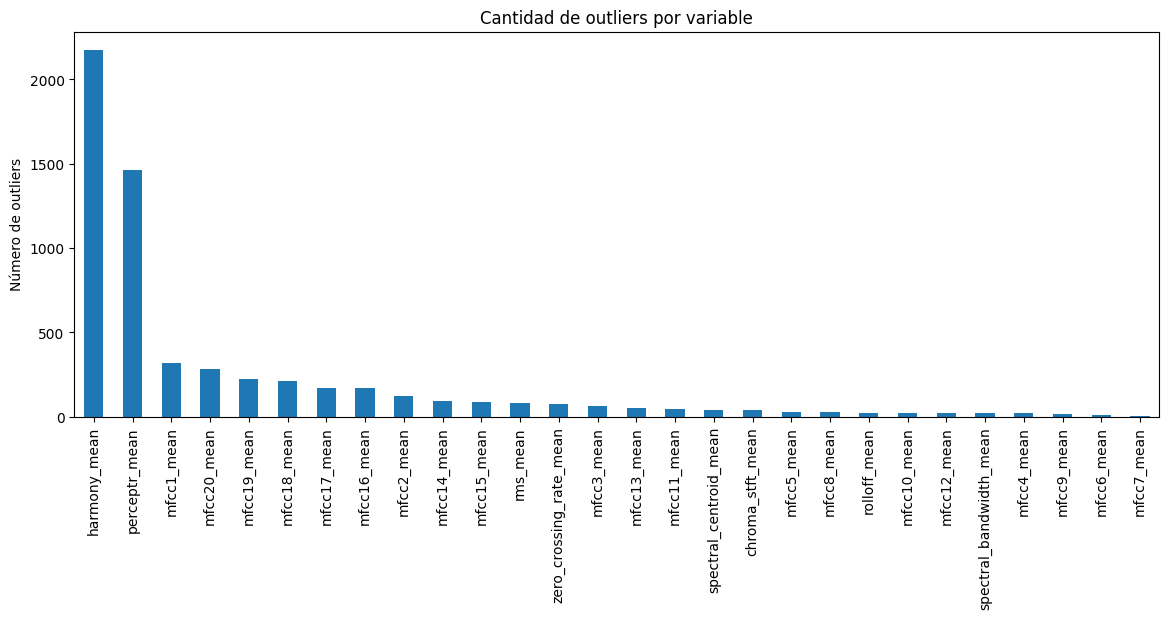

In [ ]:
mask.sum().sort_values(ascending=False).plot(
    kind="bar",
    figsize=(14,5)
)

plt.title("Cantidad de outliers por variable")
plt.ylabel("Número de outliers")
plt.xticks(rotation=90)
plt.show()

Estudio de las variables con más porcentaje de outliers, empezando por la de mayor porcentaje

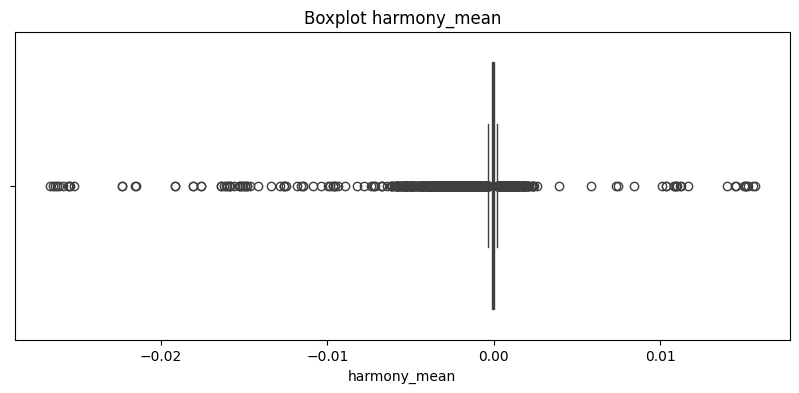

In [ ]:
plt.figure(figsize=(10,4))
sns.boxplot(x=df["harmony_mean"])

plt.title("Boxplot harmony_mean")
plt.show()

In [ ]:
fig = px.histogram(
    df,
    x="harmony_mean",
    nbins=40,
    opacity=0.7)

fig.update_layout(
    title="Distribución de harmony_mean",
    xaxis_title="harmony_mean",
    yaxis_title="Frecuencia",
    height=500,
    width=1000)

fig.show()

Harmony es una variable que tiene un histograma con colas largas pero que parecen naturales, no parece que haya grupos claramente separados, es decir, que no parecen datos erróneos o mal medidos, de hecho el rango es bastante pequeño de -0.025 a 0.015. Como es una variable que mide el contenido armónico de la música haremos una comprobación más por si acaso se refieren a un mismo género


In [ ]:
#Primero sacamos los outliers solo de Harmony y los contamos por género
Q1_h = df["harmony_mean"].quantile(0.25)
Q3_h = df["harmony_mean"].quantile(0.75)
IQR_h = Q3_h - Q1_h

mask_harmony = ((df["harmony_mean"] < (Q1_h - 1.5 * IQR_h)) | (df["harmony_mean"] > (Q3_h + 1.5 * IQR_h)))
outliers_genero = (df[mask_harmony]["label"].value_counts())

display(outliers_genero)

,count
label,
rock,377
classical,336
reggae,334
metal,311
jazz,263
disco,172
hiphop,135
blues,122
pop,119


In [ ]:
#Ahora lo vemos en porcentaje
porcentaje_genero = (df[mask_harmony].groupby("label").size()/ df.groupby("label").size()* 100).sort_values(ascending=False)

display(porcentaje_genero)

,0
label,
rock,37.775551
classical,33.667335
reggae,33.400000
metal,31.100000
jazz,26.300000
disco,17.217217
hiphop,13.527054
blues,12.200000
pop,11.900000


Queda claro que si trabajamos SIN outliers, al menos en cuanto a la varibale Harmony, vamos a eliminar un gran porcentaje de datos de casi todos los géneros por lo que trabajaremos con el dataset

#Elección de variables para ML

In [ ]:
#Identificación de la variable objetivo
var_obj ='label'

In [ ]:
#Sacamos el histograma de nuestra variable objetivo
fig = px.histogram(
    df,
    x="label",
    nbins=40,
    opacity=0.7)

fig.update_layout(
    title="Distribución de label",
    xaxis_title="label",
    yaxis_title="Frecuencia",
    height=500,
    width=1000)

fig.show()

#Esto nos dice que nuestro problema está balanceado, tenemos el mismo número de datos para cada uno de los géneros

##Método de las medias

In [ ]:
#Para elegir las 5 variables más importantes con outliers, saco las que haya una mayor diferencia entre su media mínima y máxima (las que más varían entre géneros)
cols_mean = [col for col in df.columns if col.endswith("mean")]

medias = df.groupby("label")[cols_mean].mean()

diferencia = medias.max() - medias.min()

top5 = diferencia.sort_values(ascending=False).head(5)
print(top5)



rolloff_mean               4171.813877
spectral_centroid_mean     1718.672923
spectral_bandwidth_mean    1487.271405
mfcc1_mean                  260.860533
mfcc2_mean                   78.883535
dtype: float64


Coinciden las variables más destacadas identificadas en el dataframe sin outliers con las más destacadas con outliers. Vamos a trabajar con outliers pues pueden

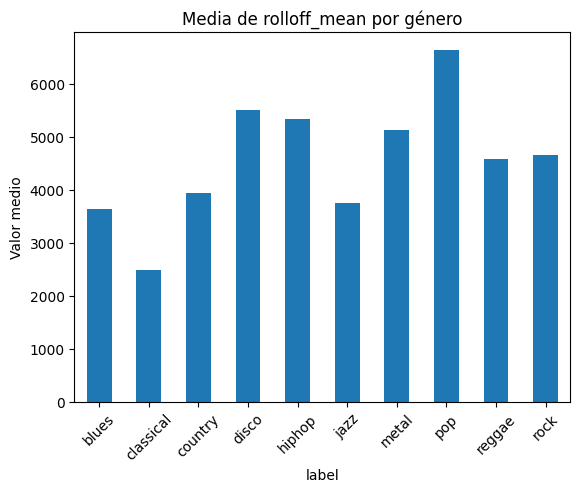

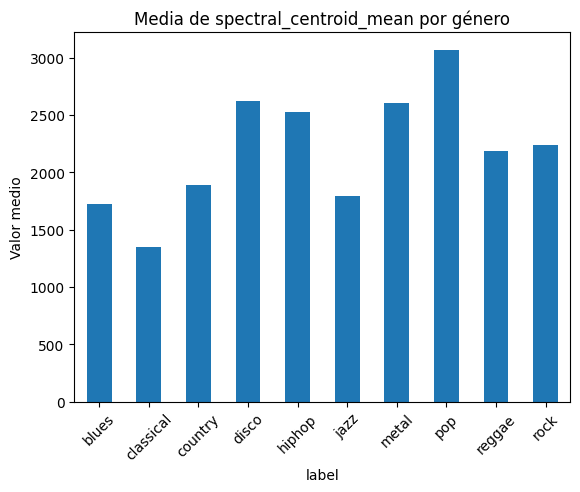

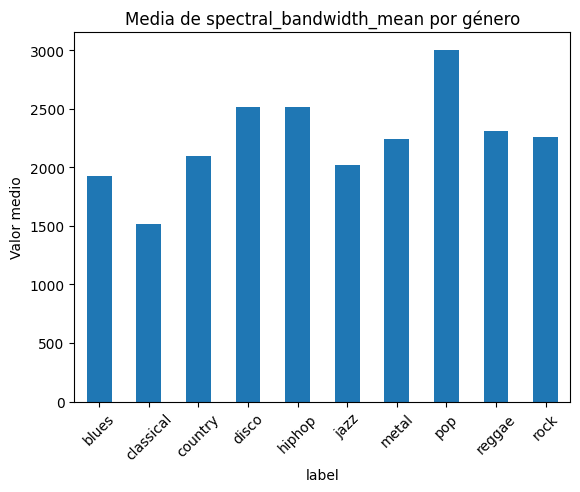

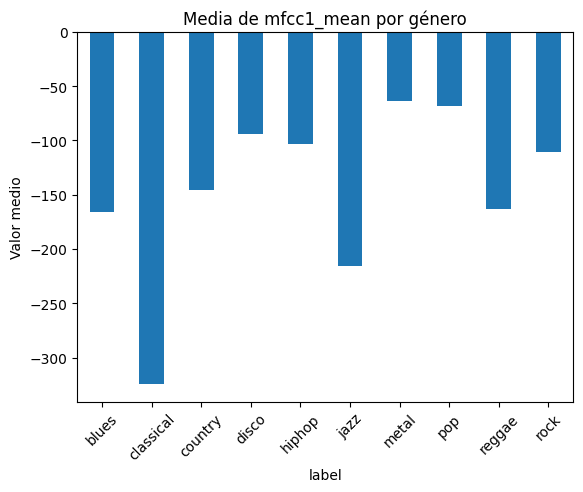

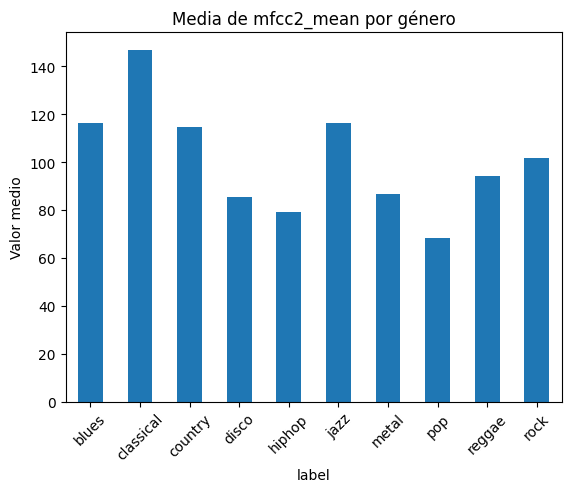

In [ ]:
#Saco gráfico de estas 5 variables para comparar entre géneros
top5_cols = top5.index
for col in top5_cols:
    df.groupby("label")[col].mean().plot(kind="bar")

    plt.title(f"Media de {col} por género")
    plt.ylabel("Valor medio")
    plt.xticks(rotation=45)

    plt.show()

In [ ]:
#Saco el ranking para posicionar los géneros en orden
for col in top5_cols:
    print(f"\n🔹 Ranking por {col}")

    ranking = df.groupby("label")[col].mean().sort_values(ascending=False).round(2)

    display(ranking)


🔹 Ranking por rolloff_mean


,rolloff_mean
label,
pop,6647.63
disco,5514.65
hiphop,5327.69
metal,5123.75
rock,4664.78
reggae,4586.94
country,3938.47
jazz,3744.72
blues,3632.91



🔹 Ranking por spectral_centroid_mean


,spectral_centroid_mean
label,
pop,3069.99
disco,2617.28
metal,2600.88
hiphop,2521.52
rock,2239.97
reggae,2182.21
country,1891.19
jazz,1790.28
blues,1726.07



🔹 Ranking por spectral_bandwidth_mean


,spectral_bandwidth_mean
label,
pop,3006.80
disco,2512.36
hiphop,2512.28
reggae,2309.80
rock,2262.22
metal,2242.82
country,2096.41
jazz,2019.76
blues,1930.85



🔹 Ranking por mfcc1_mean


,mfcc1_mean
label,
metal,-63.46
pop,-67.87
disco,-94.01
hiphop,-103.55
rock,-110.66
country,-145.95
reggae,-162.98
blues,-166.17
jazz,-215.44



🔹 Ranking por mfcc2_mean


,mfcc2_mean
label,
classical,147.04
blues,116.45
jazz,116.26
country,114.74
rock,101.85
reggae,94.29
metal,86.49
disco,85.32
hiphop,79.38


In [ ]:
#Comprobamos la correlación entre variables para ver si es necesario usar todas para ML o no
corr_top5 = df[top5_cols].corr()

display(corr_top5)

,rolloff_mean,spectral_centroid_mean,spectral_bandwidth_mean,mfcc1_mean,mfcc2_mean
rolloff_mean,1.000000,0.974360,0.951000,0.688779,-0.923652
spectral_centroid_mean,0.974360,1.000000,0.890382,0.686196,-0.931435
spectral_bandwidth_mean,0.951000,0.890382,1.000000,0.615946,-0.887156
mfcc1_mean,0.688779,0.686196,0.615946,1.000000,-0.612310
mfcc2_mean,-0.923652,-0.931435,-0.887156,-0.612310,1.000000


**Conclusiones:** Las diferencias observadas en estas variables sugieren que el pop tiende a presentar un mayor contenido de frecuencias altas y una distribución espectral más amplia, asociada a sonidos más brillantes y ricos. En cambio, la música clásica muestra valores más bajos en estas métricas, lo que indica una mayor concentración en frecuencias medias y graves y una menor dispersión espectral.

Spectral_centroid_mean, spectral_bandwidth_mean y rolloff_mean presentan una correlación muy alta entre sí, lo que indica que capturan información espectral similar relacionada con la distribución de frecuencias y la brillantez del sonido. Por tanto, en un modelo de clasificación de géneros musicales podría ser suficiente utilizar una de estas variables para reducir redundancia sin perder demasiada información.

Por último, mfcc2_mean tiene correlaciones negativas muy fuertes con las variables espectrales. Eso sugiere que aporta información distinta y probablemente muy útil para clasificación, así que esa variable sí parece especialmente valiosa mantenerla.

##Método por visualización

In [ ]:
# Primero Separamos columnas cualitativas y cuantitativas y comprobamos que se ha hecho bien:
columnas_object = df.select_dtypes(include=['object']).columns
columnas_numeric = df.select_dtypes(include=np.number).columns
columnas_object


Index(['filename', 'label'], dtype='object')

In [ ]:
#Sacamos los valores únicos de las variables numéricas por si nos interesa tratarlas como categóricas
numero_maximo_registros = 12
df_nunique_num = df[columnas_numeric].nunique().sort_values(ascending=False)
fig_nunique_num = px.bar(df_nunique_num.tail(numero_maximo_registros), orientation='h', title='Valore Unicos Más Pequeños Var. Numericas', labels={'index':'Variables Numericas'})
fig_nunique_num.update(layout_showlegend=False)

#Vemos que son muchos valores únicos para tratarlas como categóricas

In [ ]:
#Distribución de las variables numéricas. Obtenemos una automatización de los gráficos para poder visualizarlos solo cambiando más abajo el nombre de la variable que elijamos
fig_dist_num = {}
for colum in columnas_numeric:
    fig_dist_num[colum] = px.histogram(df, x=colum, color_discrete_sequence=['darkblue'], title=colum)
    fig_dist_num[colum].update_traces(opacity=0.75)

In [ ]:
columnas_numeric

Index(['length', 'chroma_stft_mean', 'chroma_stft_var', 'rms_mean', 'rms_var',
       'spectral_centroid_mean', 'spectral_centroid_var',
       'spectral_bandwidth_mean', 'spectral_bandwidth_var', 'rolloff_mean',
       'rolloff_var', 'zero_crossing_rate_mean', 'zero_crossing_rate_var',
       'harmony_mean', 'harmony_var', 'perceptr_mean', 'perceptr_var', 'tempo',
       'mfcc1_mean', 'mfcc1_var', 'mfcc2_mean', 'mfcc2_var', 'mfcc3_mean',
       'mfcc3_var', 'mfcc4_mean', 'mfcc4_var', 'mfcc5_mean', 'mfcc5_var',
       'mfcc6_mean', 'mfcc6_var', 'mfcc7_mean', 'mfcc7_var', 'mfcc8_mean',
       'mfcc8_var', 'mfcc9_mean', 'mfcc9_var', 'mfcc10_mean', 'mfcc10_var',
       'mfcc11_mean', 'mfcc11_var', 'mfcc12_mean', 'mfcc12_var', 'mfcc13_mean',
       'mfcc13_var', 'mfcc14_mean', 'mfcc14_var', 'mfcc15_mean', 'mfcc15_var',
       'mfcc16_mean', 'mfcc16_var', 'mfcc17_mean', 'mfcc17_var', 'mfcc18_mean',
       'mfcc18_var', 'mfcc19_mean', 'mfcc19_var', 'mfcc20_mean', 'mfcc20_var'],
      dtype='

In [ ]:
#Cambiando el nombre de la variable podemos ir viendo una a una
fig_dist_num['harmony_var']

In [ ]:
#Observamos la relación de las variables numéricas con la variable objetivo creando otra automatización y poder verlas una a una
fig_box_plot = {}
for colum in columnas_numeric:
    fig_box_plot[colum] = px.box(df, x=colum, color=var_obj, orientation='h')


In [ ]:
#Cambiando el nombre de la variable podemos ir comprobando la relación una a una
fig_box_plot['mfcc12_mean']

**Conclusión:** Tras analizar los boxplots de las distintas variables, se observa un notable solapamiento entre las distribuciones de los géneros musicales, lo que indica que ninguna variable individual presenta suficiente capacidad discriminatoria por sí sola. Esto sugiere que la clasificación de géneros musicales requiere la combinación de varias características de audio para obtener una separación más precisa entre categorías.

A continuación, se estudiarán las correlaciones entre variables con el objetivo de identificar aquellas que aportan información similar y podrían resultar redundantes.

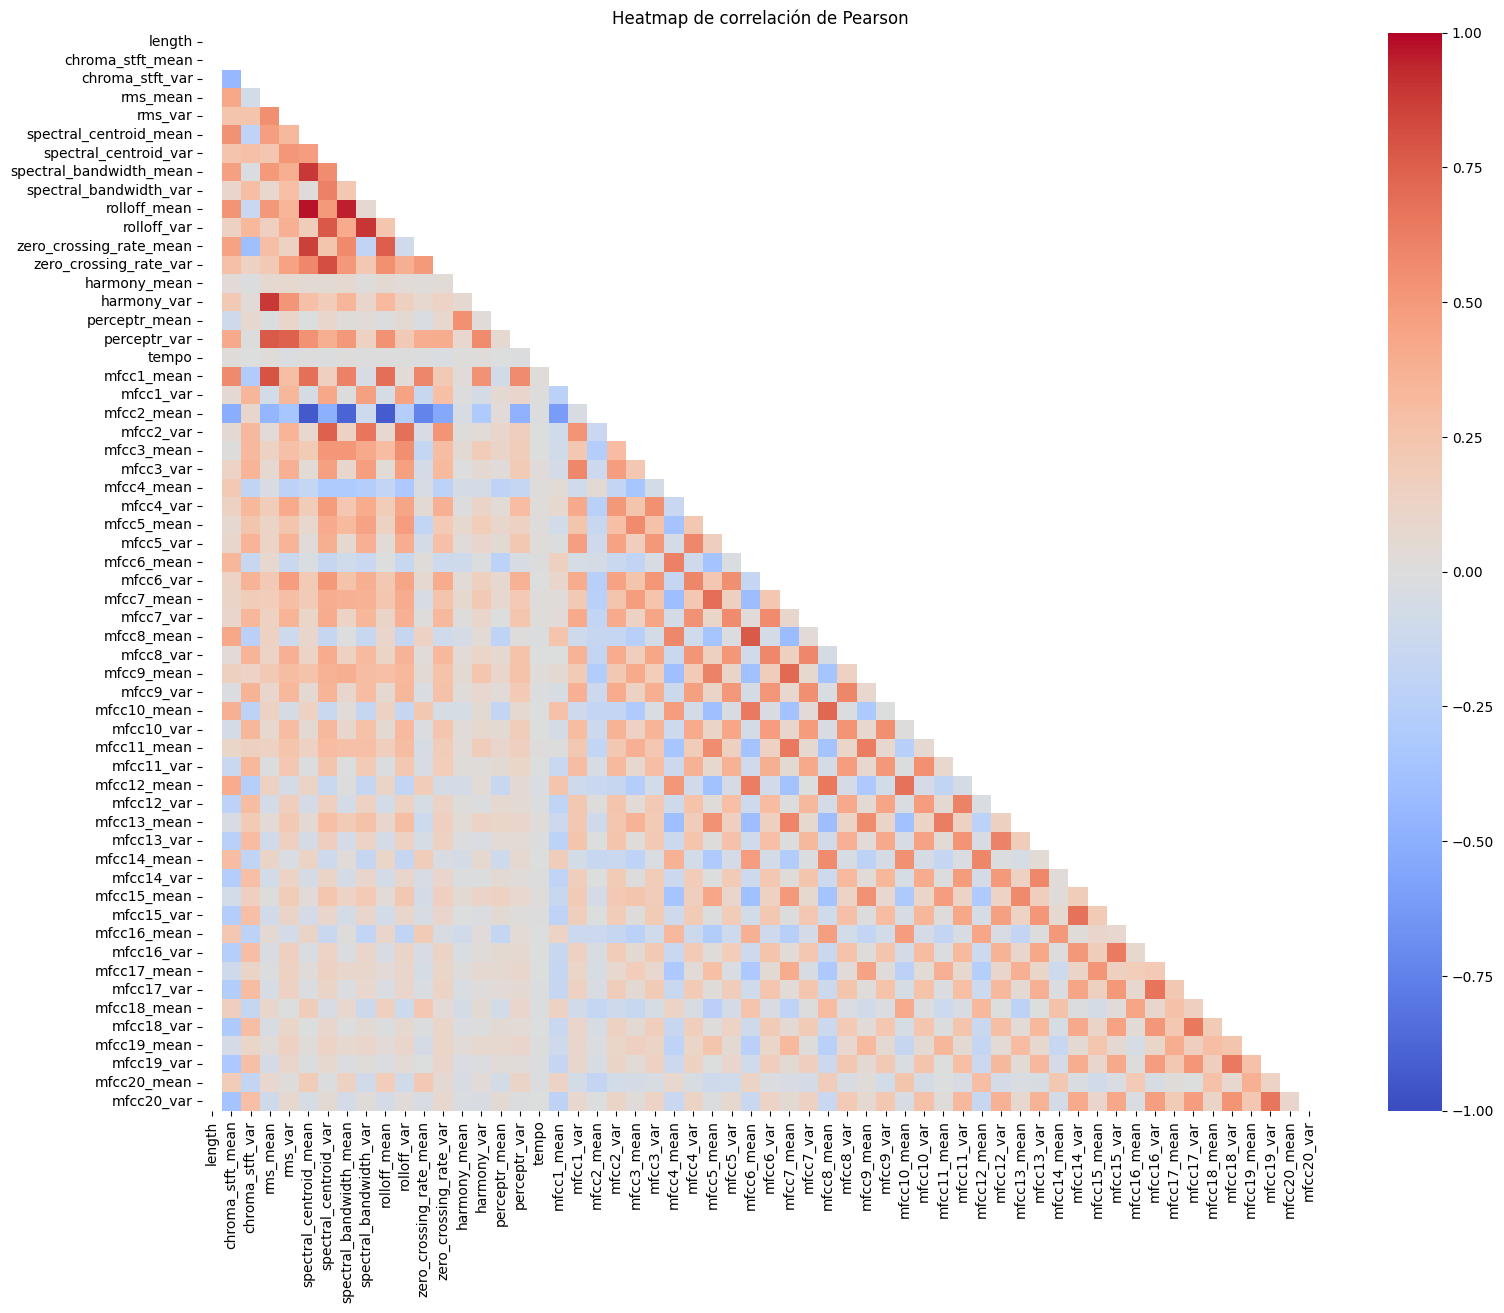

In [ ]:
#Comprobamos las correlaciones de todas las variables numéricas
corr = df[columnas_numeric].corr(method="pearson")

mask = np.triu(np.ones_like(corr, dtype=bool))


plt.figure(figsize=(18,14))

sns.heatmap(
    corr,
    mask=mask,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    annot=False
)

plt.title("Heatmap de correlación de Pearson")
plt.show()

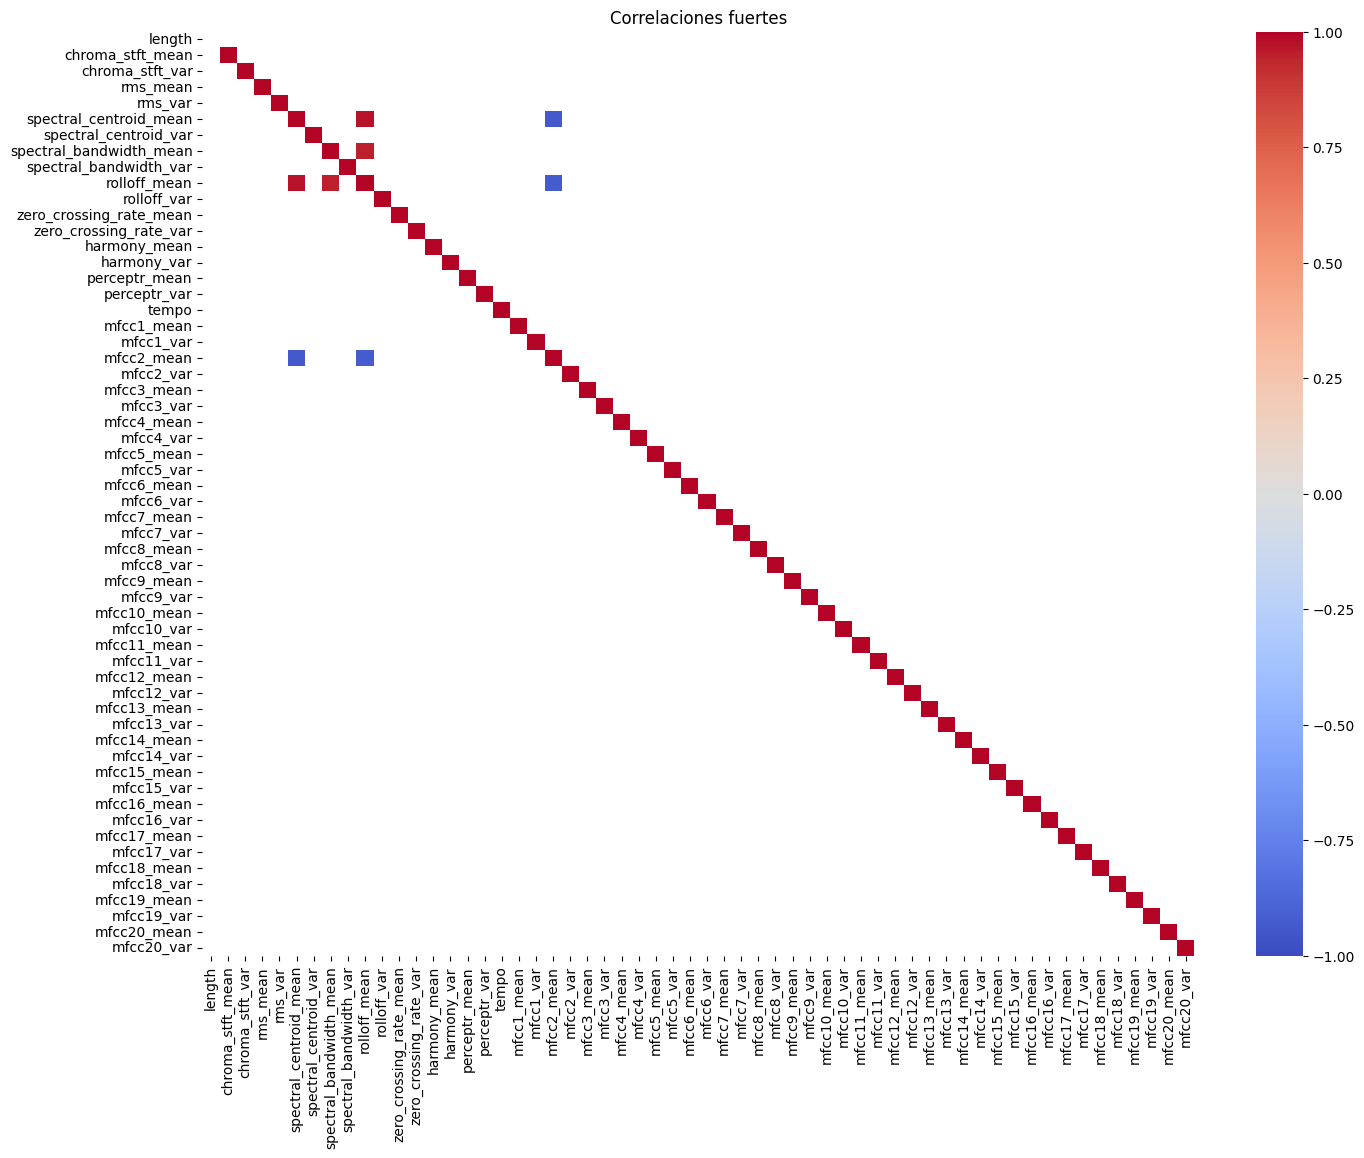

In [ ]:
#Vamos a filtrar por correlaciones fuertes
corr_filtrada = corr[(corr.abs() > 0.9)]

plt.figure(figsize=(16,12))

sns.heatmap(
    corr_filtrada,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1
)

plt.title("Correlaciones fuertes")
plt.show()

In [ ]:
#Ver los pares más fuertes
pares_fuertes = (
    corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
        .stack()
        .sort_values(ascending=False)
)

pares_fuertes = pares_fuertes[pares_fuertes.abs() > 0.9]

display(pares_fuertes)

,,0
spectral_centroid_mean,rolloff_mean,0.974360
spectral_bandwidth_mean,rolloff_mean,0.951000
rolloff_mean,mfcc2_mean,-0.923652
spectral_centroid_mean,mfcc2_mean,-0.931435


In [ ]:
df.to_csv(DATA_PROCESSED / "features_3_sec.csv", index=False)


**Conclusión**: El análisis de correlación entre las variables predictoras ha permitido identificar varios pares de variables con una correlación muy elevada (|r| > 0,9), lo que indica la existencia de información redundante. En concreto, spectral_centroid_mean y rolloff_mean presentan una correlación de 0,98, mientras que spectral_bandwidth_mean también muestra una alta correlación con ambas variables (0,96 y 0,90, respectivamente). No obstante, estas características describen aspectos muy similares del contenido espectral de audio, por lo que es esperable que presenten una fuerte relación entre sí.

La presencia de esta redundancia puede afectar especialmente a modelos lineales, como la Regresión Logística o SVM, donde la multicolinealidad puede dificultar la interpretación de los coeficientes y reducir la estabilidad del modelo. Sin embargo, otros algoritmos de clasificación, como los árboles de decisión o los métodos basados en conjuntos de árboles (por ejemplo, Random Forest), son mucho menos sensibles a este problema.

Por este motivo, en una primera fase del estudio se mantendrán todas las variables para el entrenamiento de los distintos modelos de clasificación. Posteriormente, la comparación de su rendimiento permitirá determinar si la eliminación de alguna de las variables altamente correlacionadas o la aplicación de técnicas de selección de características contribuye a mejorar la capacidad predictiva del modelo sin pérdida significativa de información.